# Brain Tumor Detection from MRI Scans
Baseline CNN vs EfficientNetB0 (transfer learning), with confusion matrix, Grad-CAM and custom image inference.

Dataset: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
Download and unzip so you have two folders: `Training/` and `Testing/`.

In [1]:
!pip install -q tensorflow matplotlib scikit-learn pandas pillow opencv-python kagglehub

In [2]:
import os, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


## 1. Load data

In [3]:
import kagglehub
DATA_DIR = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print(DATA_DIR)
print(os.listdir(DATA_DIR))   # should show Training and Testing

TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR  = os.path.join(DATA_DIR, "Testing")

IMG_SIZE = (224, 224)
BATCH    = 32
SEED     = 42

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

  0%|                                                                                       | 0.00/157M [00:00<?, ?B/s]

  1%|▌                                                                              | 1.00M/157M [00:01<03:38, 749kB/s]

  1%|▉                                                                             | 2.00M/157M [00:01<01:43, 1.56MB/s]

  2%|█▍                                                                            | 3.00M/157M [00:01<01:06, 2.42MB/s]

  3%|██▍                                                                           | 5.00M/157M [00:01<00:37, 4.24MB/s]

...

Using 4480 files for training.


Found 5600 files belonging to 4 classes.


Using 1120 files for validation.


Found 1600 files belonging to 4 classes.


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


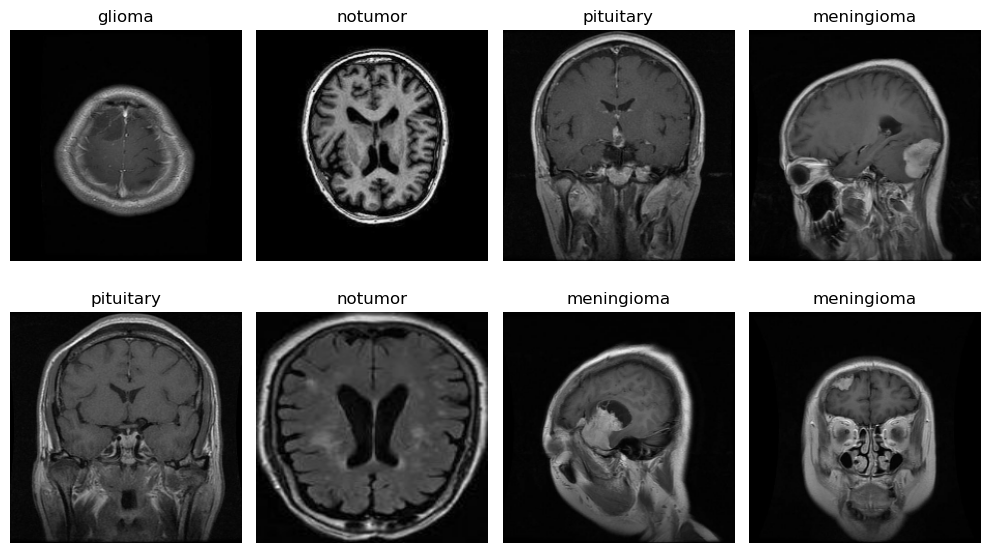

In [4]:
# Sample images
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Helper functions

In [5]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history["accuracy"], label="train"); ax[0].plot(history["val_accuracy"], label="val")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].legend()
    ax[1].plot(history["loss"], label="train"); ax[1].plot(history["val_loss"], label="val")
    ax[1].set_title(f"{title} - Loss"); ax[1].legend()
    plt.show()

def evaluate_model(model, name):
    y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
    plt.title(f"{name} - Confusion Matrix"); plt.show()
    return (y_true == y_pred).mean()

callbacks = lambda: [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
]

## 3. Model 1: Baseline CNN

In [6]:
def build_cnn():
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="baseline_cnn")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ augmentation (Sequential)            │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


  1/140 ━━━━━━━━━━━━━━━━━━━━ 13:07 6s/step - accuracy: 0.3125 - loss: 1.3889

  2/140 ━━━━━━━━━━━━━━━━━━━━ 1:28 643ms/step - accuracy: 0.3047 - loss: 1.3847

  3/140 ━━━━━━━━━━━━━━━━━━━━ 1:18 572ms/step - accuracy: 0.2865 - loss: 1.3874

  4/140 ━━━━━━━━━━━━━━━━━━━━ 1:14 548ms/step - accuracy: 0.2754 - loss: 1.3892

...

138/140 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.8317 - loss: 0.4504

139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.8317 - loss: 0.4505

140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.8316 - loss: 0.4505

140/140 ━━━━━━━━━━━━━━━━━━━━ 65s 463ms/step - accuracy: 0.8266 - loss: 0.4601 - val_accuracy: 0.7830 - val_loss: 0.5633 - learning_rate: 9.0000e-05


Training time: 21.7 min


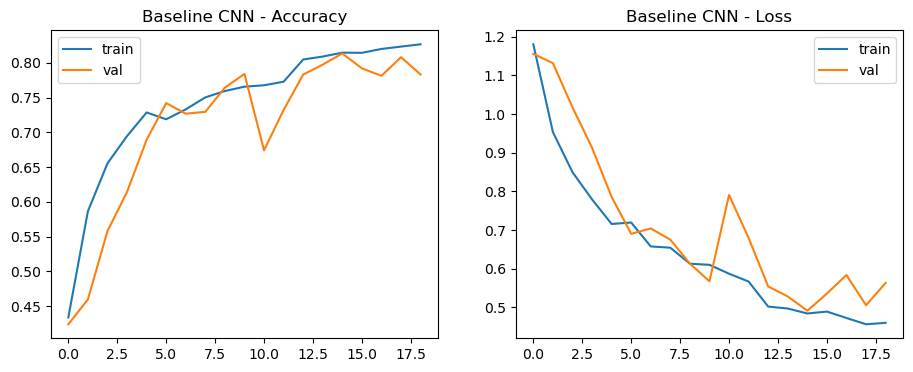

In [7]:
t0 = time.time()
h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=25, callbacks=callbacks())
cnn_time = time.time() - t0
print(f"Training time: {cnn_time/60:.1f} min")
plot_history(h_cnn.history, "Baseline CNN")

              precision    recall  f1-score   support

      glioma     0.8797    0.5300    0.6615       400
  meningioma     0.6616    0.4350    0.5249       400
     notumor     0.6557    0.9950    0.7905       400
   pituitary     0.7812    0.9550    0.8594       400

    accuracy                         0.7288      1600
   macro avg     0.7445    0.7288    0.7091      1600
weighted avg     0.7445    0.7288    0.7091      1600



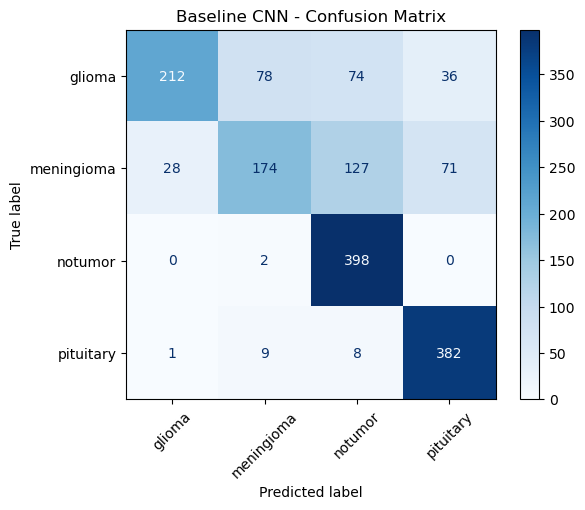

Test accuracy: 0.72875


In [8]:
cnn_acc = evaluate_model(cnn, "Baseline CNN")
print("Test accuracy:", cnn_acc)

## 4. Model 2: EfficientNetB0 (Transfer Learning)
Stage 1: train the new head with the base frozen. Stage 2: fine-tune the top layers.

In [9]:
base = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base.trainable = False

inp = keras.Input((*IMG_SIZE, 3))
x = augment(inp)
x = base(x, training=False)          # EfficientNet has built-in rescaling (expects 0-255)
gap  = layers.GlobalAveragePooling2D()
drop = layers.Dropout(0.3)
out_layer = layers.Dense(NUM_CLASSES, activation="softmax")
x = gap(x); x = drop(x); out = out_layer(x)
tl_model = keras.Model(inp, out, name="efficientnetb0_tl")

tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="categorical_crossentropy", metrics=["accuracy"])

       0/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/16705208 ━━━━━━━━━━━━━━━━━━━━ 2:20 8us/step

   32768/16705208 ━━━━━━━━━━━━━━━━━━━━ 1:57 7us/step

   49152/16705208 ━━━━━━━━━━━━━━━━━━━━ 2:01 7us/step

   65536/16705208 ━━━━━━━━━━━━━━━━━━━━ 1:47 6us/step

...

15499264/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

15843328/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

16171008/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

16416768/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Epoch 1/8


  1/140 ━━━━━━━━━━━━━━━━━━━━ 42:30 18s/step - accuracy: 0.4688 - loss: 1.2171

  2/140 ━━━━━━━━━━━━━━━━━━━━ 1:20 586ms/step - accuracy: 0.4375 - loss: 1.2312

  3/140 ━━━━━━━━━━━━━━━━━━━━ 1:16 562ms/step - accuracy: 0.4340 - loss: 1.2313

  4/140 ━━━━━━━━━━━━━━━━━━━━ 1:16 566ms/step - accuracy: 0.4271 - loss: 1.2434

...

138/140 ━━━━━━━━━━━━━━━━━━━━ 1s 519ms/step - accuracy: 0.9092 - loss: 0.2538

139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.9091 - loss: 0.2539

140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.9091 - loss: 0.2540

140/140 ━━━━━━━━━━━━━━━━━━━━ 88s 626ms/step - accuracy: 0.9031 - loss: 0.2636 - val_accuracy: 0.8875 - val_loss: 0.2944 - learning_rate: 1.0000e-05


Training time: 28.1 min


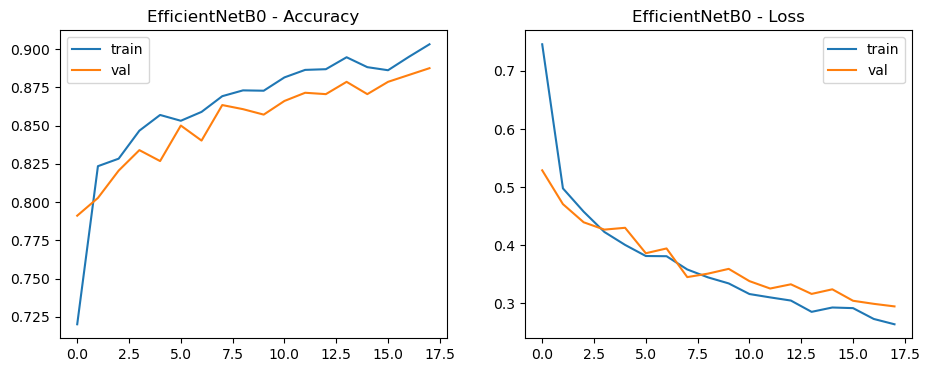

In [10]:
# Stage 1: train head
t0 = time.time()
h1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks())

# Stage 2: fine-tune top layers (keep BatchNorm frozen)
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss="categorical_crossentropy", metrics=["accuracy"])
h2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks())
tl_time = time.time() - t0
print(f"Training time: {tl_time/60:.1f} min")

hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
plot_history(hist, "EfficientNetB0")

              precision    recall  f1-score   support

      glioma     0.8718    0.6800    0.7640       400
  meningioma     0.8000    0.6600    0.7233       400
     notumor     0.8955    0.9850    0.9381       400
   pituitary     0.7625    0.9875    0.8606       400

    accuracy                         0.8281      1600
   macro avg     0.8324    0.8281    0.8215      1600
weighted avg     0.8324    0.8281    0.8215      1600



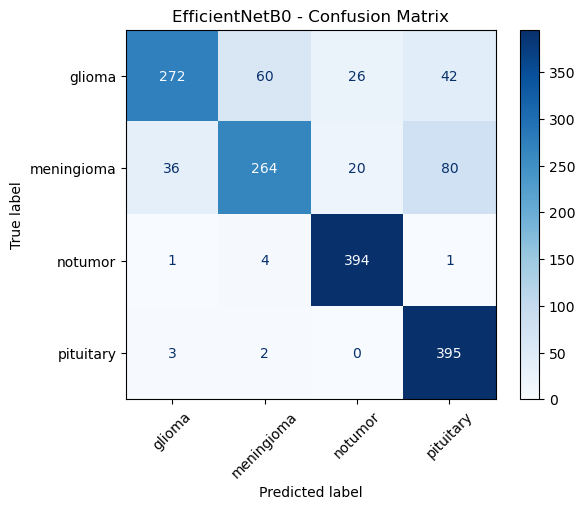

Test accuracy: 0.828125


In [11]:
tl_acc = evaluate_model(tl_model, "EfficientNetB0")
print("Test accuracy:", tl_acc)

## 5. Comparison

In [12]:
comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "EfficientNetB0"],
    "Parameters": [cnn.count_params(), tl_model.count_params()],
    "Training time (min)": [round(cnn_time / 60, 1), round(tl_time / 60, 1)],
    "Test accuracy": [round(cnn_acc, 4), round(tl_acc, 4)],
})
comparison

,Model,Parameters,Training time (min),Test accuracy
0,Baseline CNN,421828,21.7,0.7288
1,EfficientNetB0,4054695,28.1,0.8281


## 6. Inference on a custom MRI image + Grad-CAM

Prediction: pituitary  |  Confidence: 53.39%
  glioma        38.58%
  meningioma     2.45%
  notumor        5.58%
  pituitary     53.39%


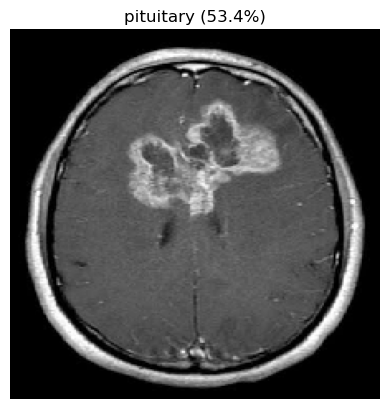

Prediction: pituitary  |  Confidence: 53.39%
  glioma        38.58%
  meningioma     2.45%
  notumor        5.58%
  pituitary     53.39%


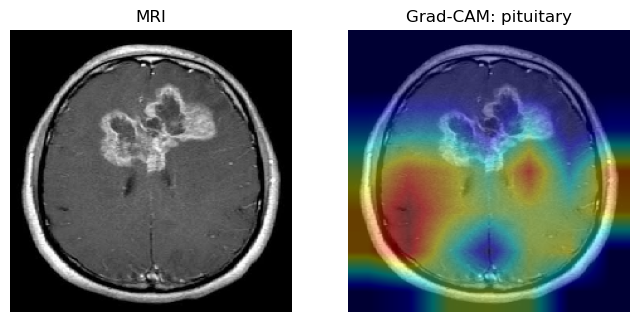

In [13]:
import cv2

def predict_image(path, model=tl_model, show=True):
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)   # 0-255 range
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    print(f"Prediction: {class_names[idx]}  |  Confidence: {probs[idx]*100:.2f}%")
    for n, p in zip(class_names, probs):
        print(f"  {n:12s} {p*100:6.2f}%")
    if show:
        plt.imshow(img); plt.axis("off")
        plt.title(f"{class_names[idx]} ({probs[idx]*100:.1f}%)"); plt.show()
    return arr, idx

def grad_cam(path, alpha=0.4):
    arr, idx = predict_image(path, show=False)
    feat_model = keras.Model(base.input, base.output)
    with tf.GradientTape() as tape:
        conv = feat_model(arr)
        tape.watch(conv)
        preds = out_layer(drop(gap(conv), training=False))
        loss = preds[:, idx]
    grads = tape.gradient(loss, conv)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(conv[0] * weights, axis=-1).numpy()
    cam = np.maximum(cam, 0); cam /= (cam.max() + 1e-8)
    cam = cv2.resize(cam, IMG_SIZE)
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(arr[0] * (1 - alpha) + heat * alpha)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(arr[0].astype("uint8")); ax[0].set_title("MRI"); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title(f"Grad-CAM: {class_names[idx]}"); ax[1].axis("off")
    plt.show()

# >>> Put the path of any MRI image here <<<
test_image = os.path.join(TEST_DIR, "glioma", os.listdir(os.path.join(TEST_DIR, "glioma"))[0])
predict_image(test_image)
grad_cam(test_image)

In [14]:
# Save model for a later demo app
tl_model.save("brain_tumor_efficientnetb0.keras")
print("Saved.")

Saved.


**Disclaimer:** This model is a screening aid for educational purposes, not a medical diagnostic tool.